# NicheJEPA Tutorial xhs1000-skin

- Creator: Sebastian Birk (sb75@sanger.ac.uk) Mohammad Vali Sanian (mohammad.sanian@helsinki.fi)
- Date of Creation: 30.06.2025
- Date of Last Modification: 08.07.2025 (by Mohammad Vali Sanian mohammad.sanian@helsinki.fi)

## 1. Setup

### 1.1 Load Libraries 

In [40]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
sys.path.append("../../utils")

In [2]:
import logging
import os
import warnings
from typing import List, Tuple
import torch
from sklearn.metrics import silhouette_score
import gseapy as gp
from sklearn.metrics.pairwise import cosine_similarity

import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from datasets import load_from_disk
from matplotlib.colors import Normalize
import squidpy as sq
from tqdm import tqdm
from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_gene_embed,
                       get_average_gene_embed,
                       get_spatial_score,
                       get_emd_distance )
from nichejepa.utils.evaluation import (get_top_gene_score,
                                        get_top_gene_pairs
                                        )
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(


In [3]:
## This function takes a list of cell_ids and returns the corresponding dataset object.
def subset_by_cell_ids(dataset, cell_id_list):
    cell_id_set = set(cell_id_list)
    cell_ids = dataset['cell_id']
    indices = [i for i, cid in tqdm(enumerate(cell_ids), total=len(cell_ids), desc="Finding matching indices") if cid in cell_id_set]
    return dataset.select(indices)


In [6]:
import os

import anndata as ad
import omnipath as op
import pandas as pd
from cellphonedb.utils import db_releases_utils, db_utils
from IPython.display import HTML, display


def get_adata_cellphonedb_lr_pairs(
        adata: ad.AnnData,
        save_folder_path: str,
        cpdb_version: str = 'v5.0.0',
        ) -> pd.DataFrame:
    """
    Retrieve ligand-receptor pairs from CellPhoneDB
    (https://www.cellphonedb.org/) that are present in an AnnData object.

    Parameters
    -----------
    adata:
        The AnnData object to check for gene availability
    save_folder_path

    Returns
    -----------
    lr_interaction_df:
        A DataFrame containing ligand and receptor pairs present in the
        AnnData object.
    """
    # Display CellPhoneDB version
    display(HTML(db_releases_utils.get_remote_database_versions_html()[
        'db_releases_html_table']))

    # Path where the input files to generate the database are/will be located
    os.makedirs(save_folder_path, exist_ok=True)
    cpdb_target_dir = os.path.join(save_folder_path, cpdb_version)

    # Download the CellPhoneDB database
    db_utils.download_database(cpdb_target_dir, cpdb_version)

    # Retrieve CellPhoneDB interactions
    intercell_df = pd.read_csv(f'{cpdb_target_dir}/interaction_input.csv')

    # Filter for lr interactions
    lr_interaction_df = intercell_df[
        intercell_df['directionality'] == 'Ligand-Receptor']

    # Remove interactions involving protein complexes
    lr_interaction_df = lr_interaction_df[
        ~lr_interaction_df['interactors'].apply(lambda x: '+' in x)]

    # Only keep ligand and receptor gene names
    lr_interaction_df['ligand'] = lr_interaction_df[
        'interactors'].apply(lambda x: x.split('-')[0])
    lr_interaction_df['receptor'] = lr_interaction_df[
        'interactors'].apply(lambda x: x.split('-')[1])
    lr_interaction_df = lr_interaction_df[['ligand', 'receptor']]

    # Map gene names to ensembl IDs, keeping only genes present in the AnnData
    # object
    lr_interaction_df['ligand'] = lr_interaction_df[
        'ligand'].map(adata.var['ensembl_id'])
    lr_interaction_df['receptor'] = lr_interaction_df[
        'receptor'].map(adata.var['ensembl_id'])

    print()

    # Drop interactions where ligand or receptor is not in the AnnData object
    lr_interaction_df = lr_interaction_df.dropna()

    return lr_interaction_df


def get_adata_omnipath_lr_pairs(
        adata: ad.AnnData,
        min_curation_effort: int = 2
        ) -> pd.DataFrame:
    """
    Retrieve ligand-receptor pairs from OmniPath (https://omnipathdb.org/) that
    are present in an AnnData object.

    Parameters
    -----------
    adata:
        The AnnData object to check for gene availability
    min_curation_effort:
        Minimum curation effort parameter of the OmniPath database.

    Returns
    -----------
    lr_interaction_df:
        A DataFrame containing ligand and receptor pairs present in the
        AnnData object.
    """
    # Retrieve OmniPath interactions
    intercell_df = op.interactions.import_intercell_network(
        include=['omnipath', 'pathwayextra', 'ligrecextra'])

    # Filter for lr interactions
    lr_interaction_df = intercell_df[
        (intercell_df['category_intercell_source'] == 'ligand') &
        (intercell_df['category_intercell_target'] == 'receptor')]

    # Filter for minimum curation effort
    lr_interaction_df = lr_interaction_df[
        lr_interaction_df['curation_effort'] >= min_curation_effort]

    # Remove interactions involving protein complexes
    lr_interaction_df = lr_interaction_df[
        ~lr_interaction_df['genesymbol_intercell_source'].apply(
            lambda x: 'COMPLEX' in x)]
    lr_interaction_df = lr_interaction_df[
        ~lr_interaction_df['genesymbol_intercell_target'].apply(
            lambda x: 'COMPLEX' in x)]

    # Only keep ligand and receptor gene names
    lr_interaction_df = lr_interaction_df[
        ['genesymbol_intercell_source', 'genesymbol_intercell_target']]

    # Map gene names to ensembl IDs, keeping only genes present in the AnnData
    # object
    lr_interaction_df['ligand'] = lr_interaction_df[
        'genesymbol_intercell_source'].map(adata.var['ensembl_id'])
    lr_interaction_df['receptor'] = lr_interaction_df[
        'genesymbol_intercell_target'].map(adata.var['ensembl_id'])
    lr_interaction_df.drop(
        ['genesymbol_intercell_source', 'genesymbol_intercell_target'],
        axis=1,
        inplace=True)

    # Drop interactions where ligand or receptor is not in the AnnData object
    lr_interaction_df = lr_interaction_df.dropna()

    return lr_interaction_df

INFO:root:Downloading data from `https://omnipathdb.org/queries/enzsub?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/interactions?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/complexes?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/annotations?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/intercell?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/about?format=text`


In [7]:
lr_database = 'cellphonedb'

### 1.2 Configure Paths

In [9]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055'

### 1.3 Define Config

In [10]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [11]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [12]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [13]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [14]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'
sc.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)


In [ ]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhs1000-skin

In [15]:
dataset_name = 'xhs1000-39b_1p'
cell_type_key = 'niche_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch19.h5ad'

#### 2.1.1 Load Data

In [16]:
adata = sc.read_h5ad(file_path)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


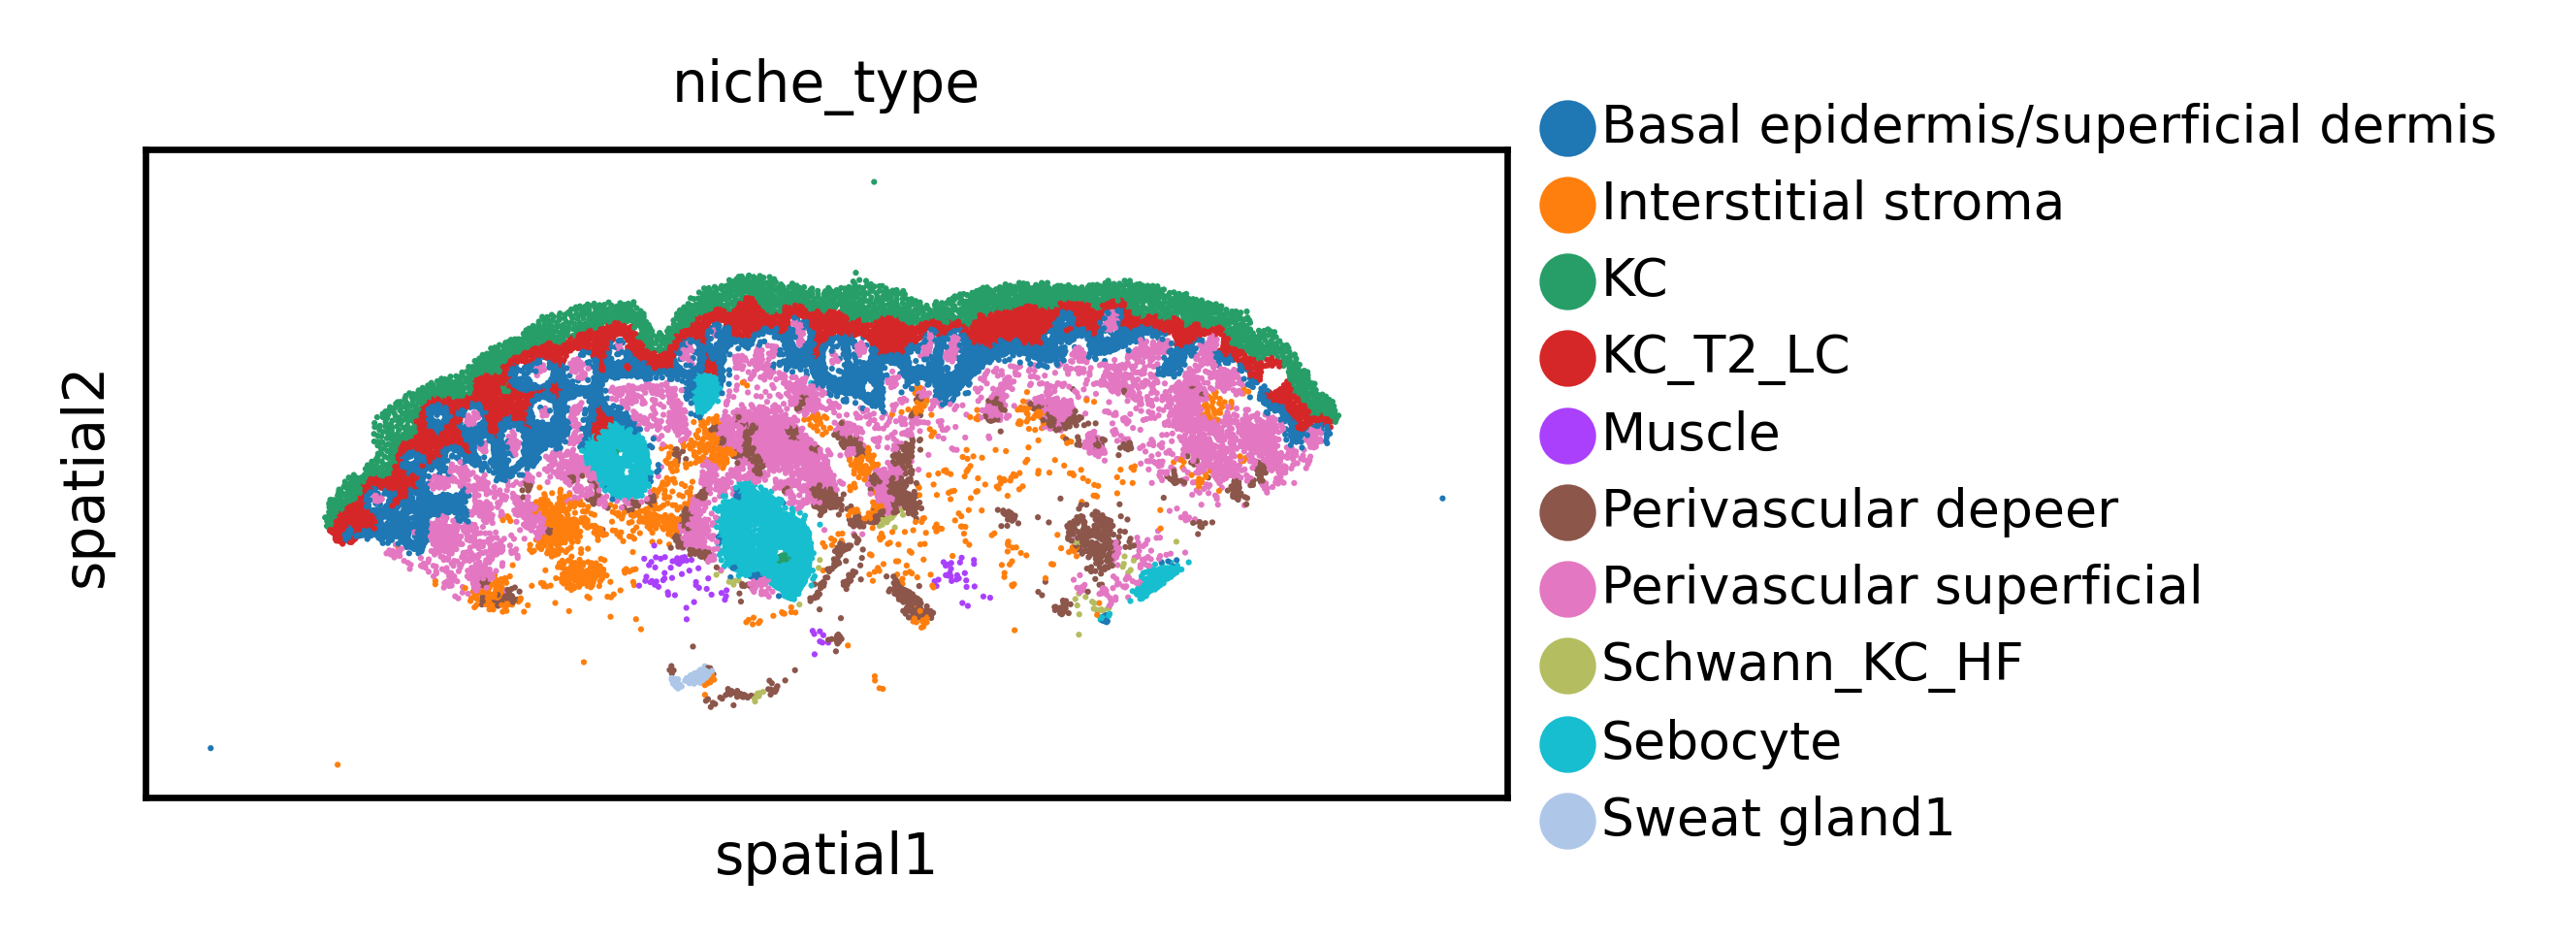

In [20]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')


In [21]:
lr_interaction_df

,ligand,receptor
2,ENSG00000039068,ENSG00000139187
4,ENSG00000170558,ENSG00000104921
232,ENSG00000090339,ENSG00000005844
237,ENSG00000108622,ENSG00000090659
239,ENSG00000076662,ENSG00000090659
...,...,...
2895,ENSG00000170893,ENSG00000174417
2900,ENSG00000204936,ENSG00000261371
2901,ENSG00000196776,ENSG00000198053
2902,ENSG00000196776,ENSG00000089012


In [ ]:
gene = "EEF1G"   # replace with your gene of interest
# slice out the single‑column sparse view
counts_sparse = adata[:, gene].X  

# turn it into a dense 2D array, then .ravel() to 1D
counts = counts_sparse.toarray().ravel()

# store in adata.obs and plot
adata.obs[gene + "_counts"] = counts
sc.pl.spatial(
    adata,
    color=gene + "_counts",
    spot_size=spot_size,
    use_raw=False
)


#### 2.1.2 Harmonize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [15]:
adata = harmonize_adata(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


#### 2.1.3 Tokenize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [16]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/mv10/nemo_v6/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...


Map (num_proc=4):   0%|          | 0/17384 [00:00<?, ? examples/s]

#### 2.1.4 Save Tokenize Data

In [17]:
num_shards = 32
save_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'

In [18]:
!mkdir save_dataset_path

In [19]:
dataset.save_to_disk(
            save_dataset_path,
            num_shards=num_shards)

Saving the dataset (0/32 shards):   0%|          | 0/17384 [00:00<?, ? examples/s]

#### 2.1.5 Load Tokenize Data

In [22]:
load_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}'
dataset = load_from_disk(load_dataset_path)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [23]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 17384
})

#### 2.1.6 Embed Data

In [14]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

In [24]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
136it [02:35,  1.14s/it]


In [25]:
adata.obsm['cell_emb'] = output_embed['cell_emb']
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


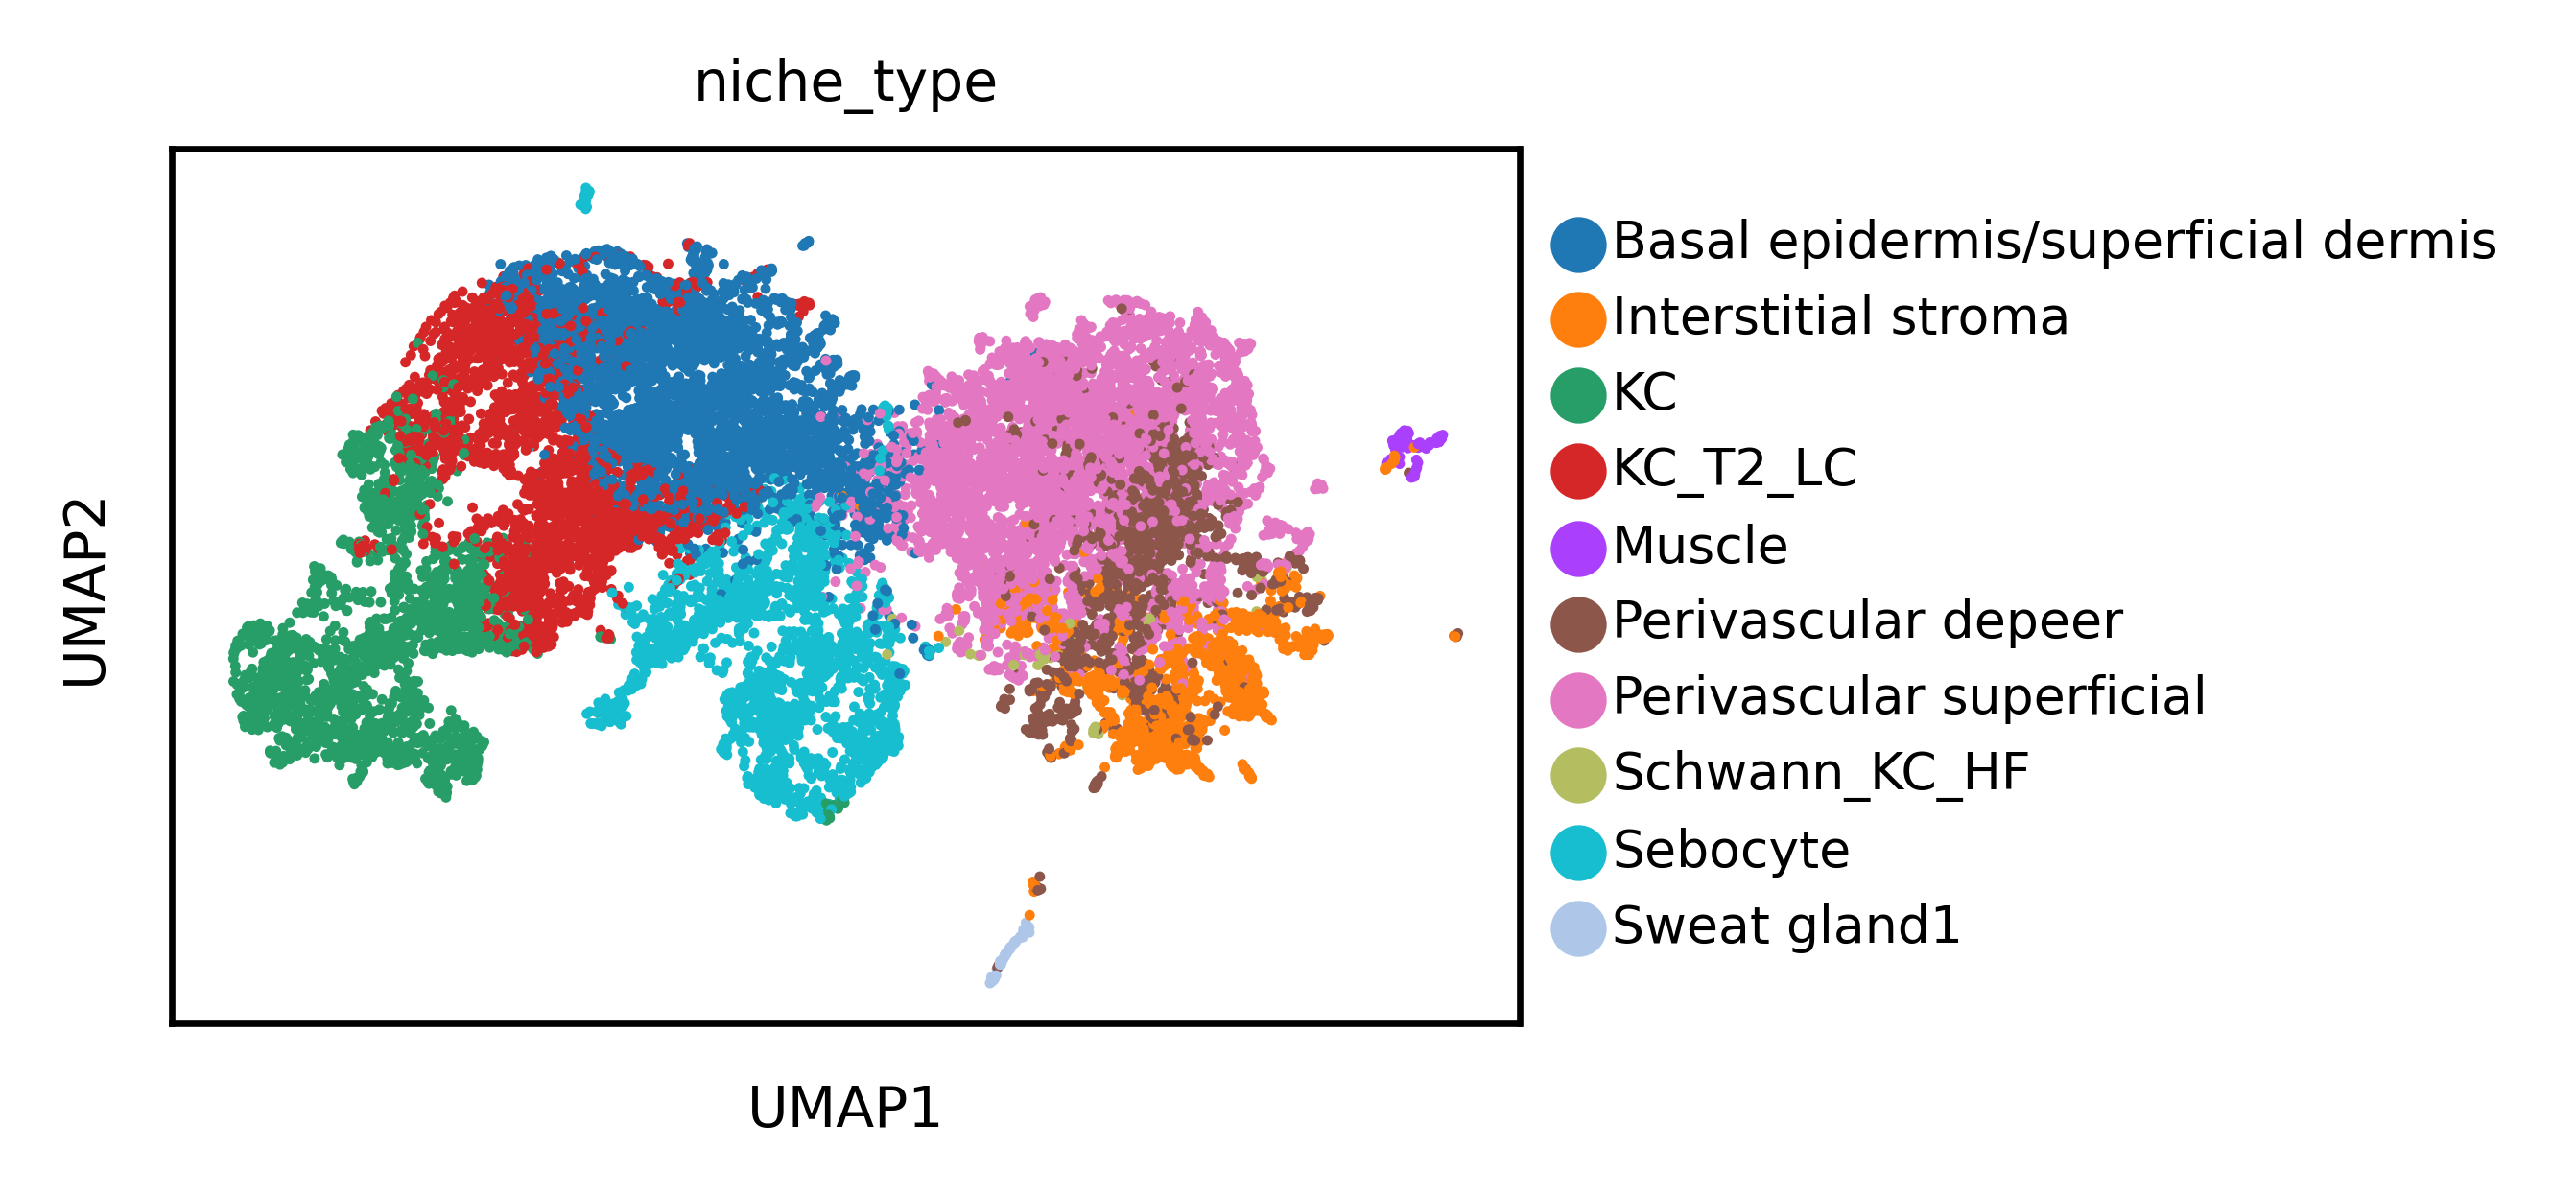

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


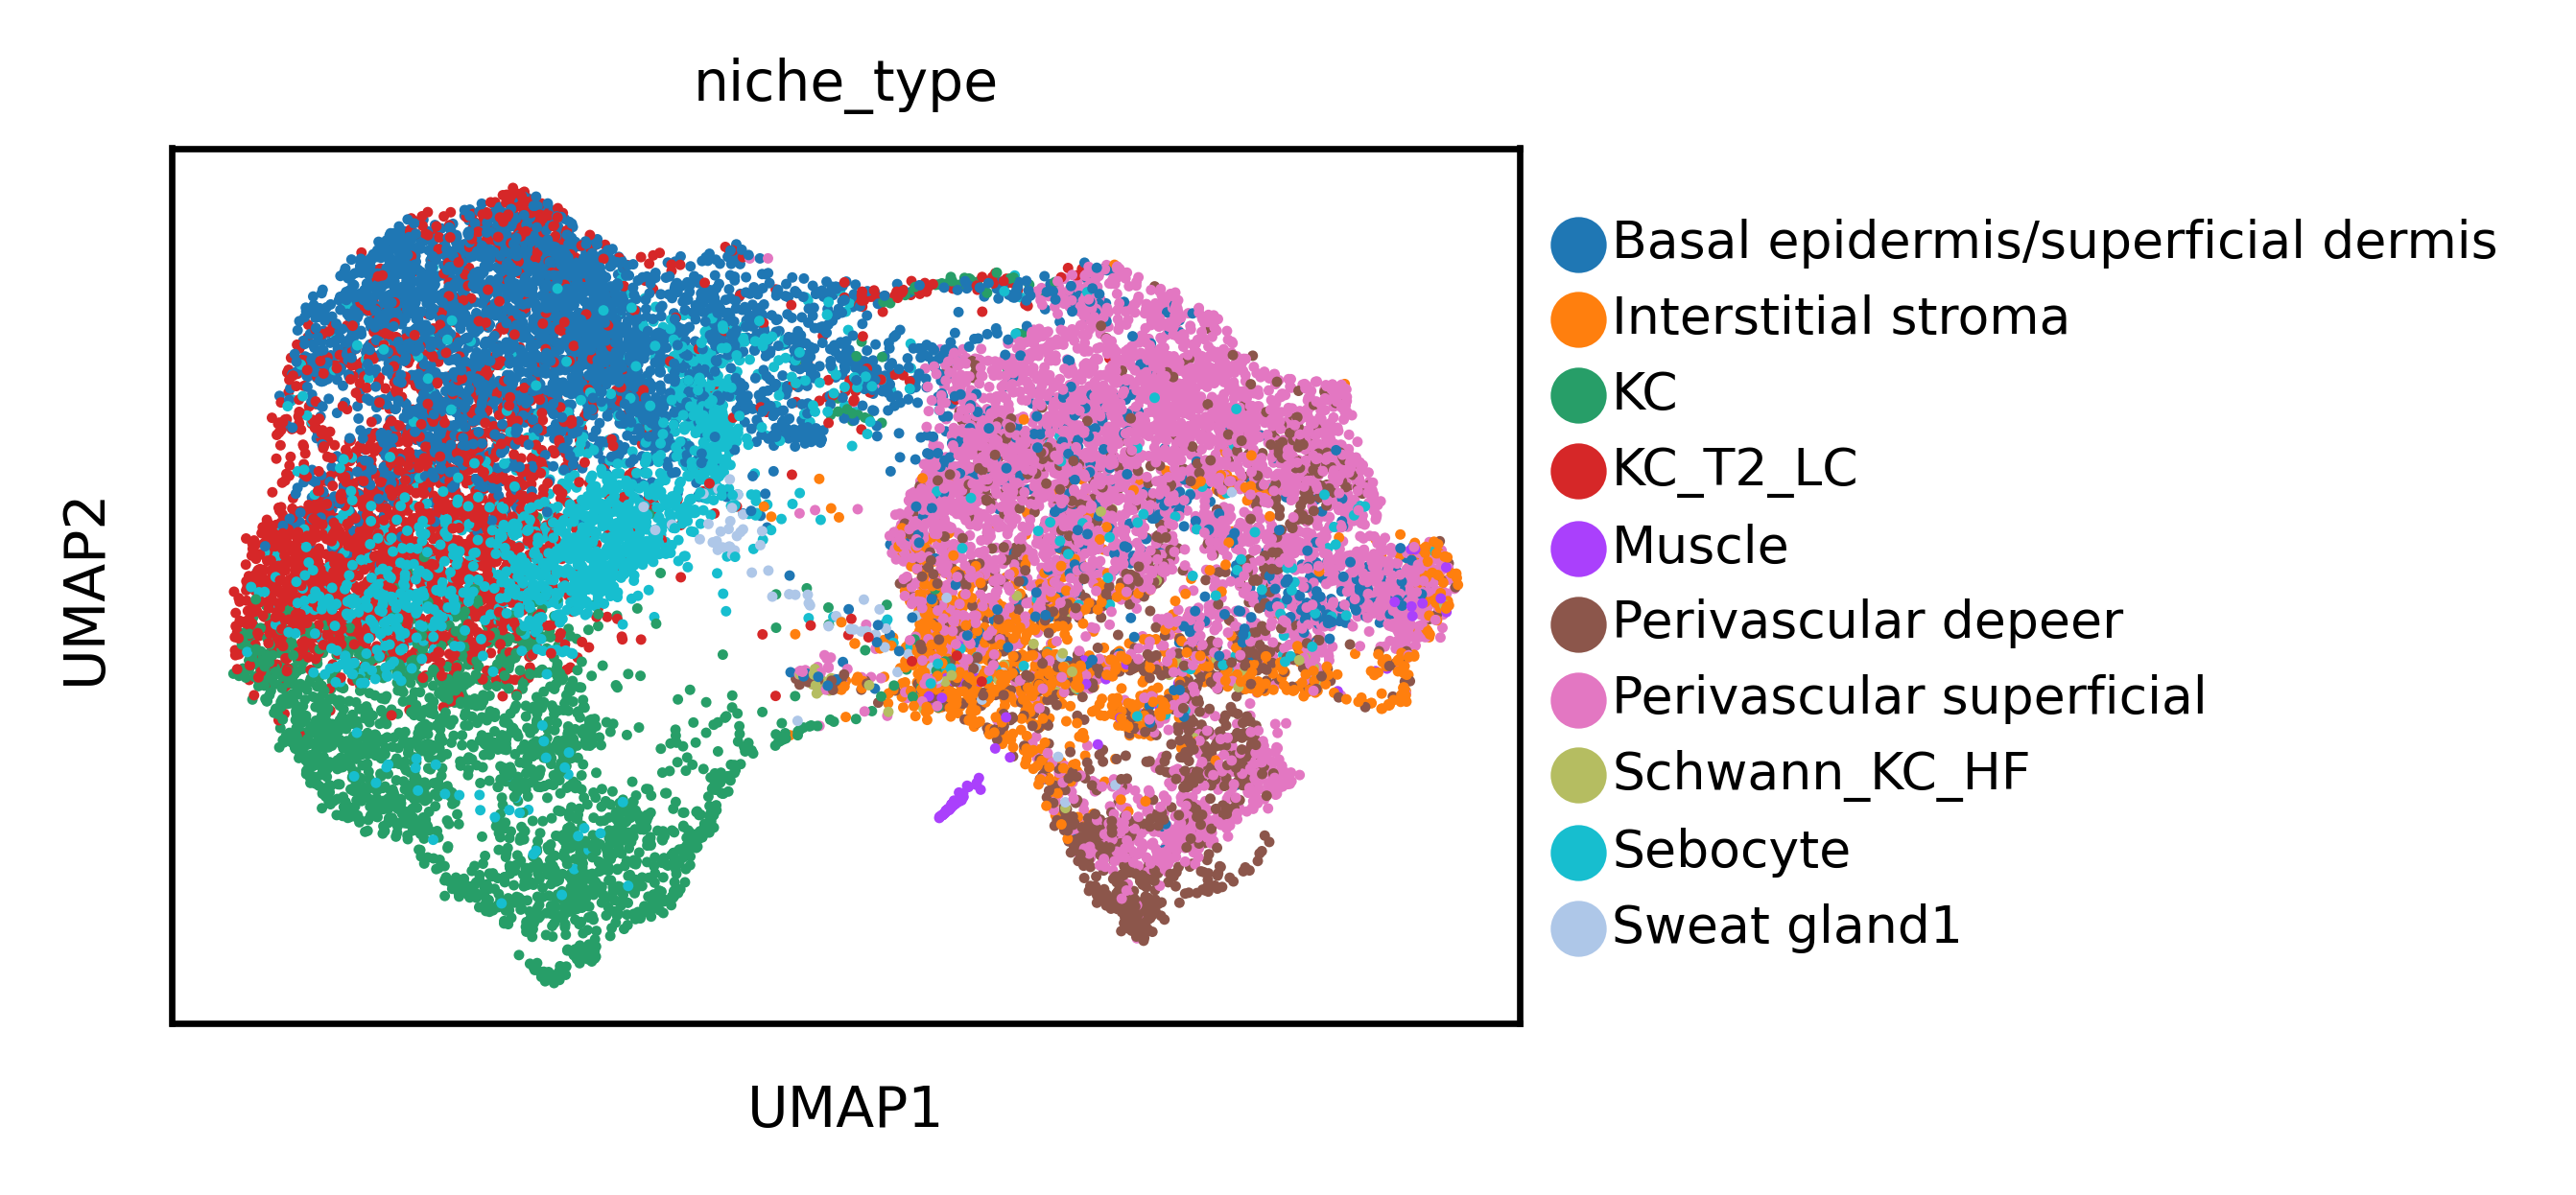

In [26]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')
# Store the neighborhood UMAP with a custom key
adata.obsm['neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')
# Store the cell UMAP with a custom key
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='cell',
           color=label)


#### 2.1.7 Niche Identification

In [59]:
# Set dataset params
batch_key = 'batch'
emb_key = 'cell'
latent_leiden_resolution = 0.3
spot_sizes = [0.3, 30]

latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'


In [60]:
# Compute UMAP representation for (aggregated) gene embeddings
if F'{emb_key}_connectivities' not in adata.obsp.keys():
    print("Computing sc.pp.neighbors...")
    sc.pp.neighbors(adata,
                    n_neighbors=15,
                    use_rep=f'{emb_key}_emb_layer_{layer}',
                    key_added=emb_key)
if f'{emb_key}_umap' not in adata.obsm.keys():
    print("Computing sc.tl.umap...")
    sc.tl.umap(adata,
               neighbors_key=emb_key,
               key_added=f'{emb_key}_umap')


In [61]:
sc.tl.leiden(adata,
             neighbors_key=emb_key,
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


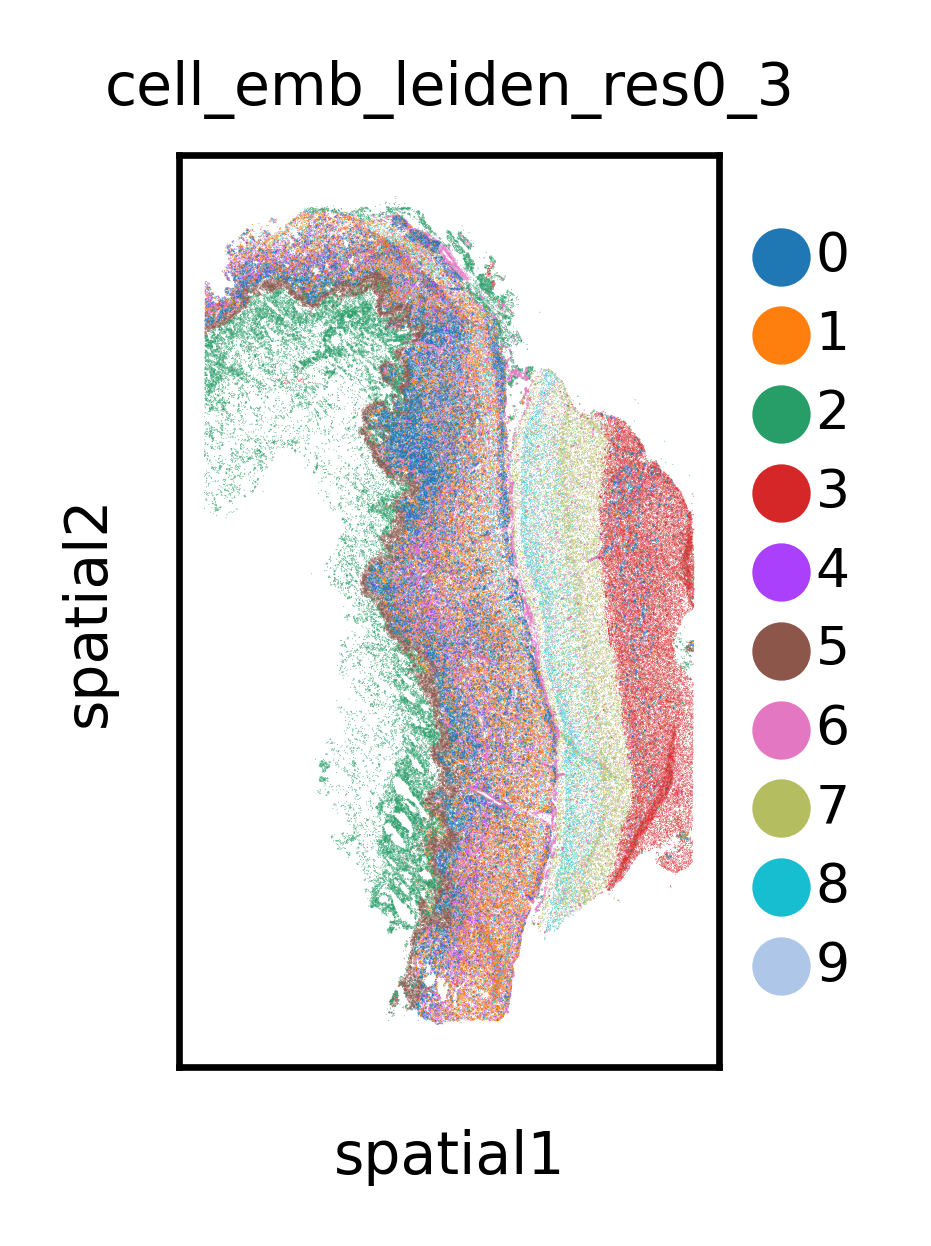

In [62]:
sc.pl.spatial(
    adata,
    color=latent_cluster_key,
    spot_size=spot_size,
    save=f'{dataset_name}_{latent_cluster_key}.svg'
)

#### get summery of gene_experesion on this data

In [15]:
def summarize_gene_expression(
    adata,
    subset_cell_ids: list,
    top_n: int = 10,
    ensembl_col: str = "ensembl_id"
):
    """
    Filter AnnData to a subset of cells, compute gene expression summaries,
    and return top expressed genes with Ensembl IDs.

    Args:
        adata (AnnData): Pre-loaded AnnData object.
        subset_cell_ids (list): List of cell IDs to filter.
        top_n (int): Number of top expressed genes to return.
        ensembl_col (str): Column in adata.var that contains Ensembl IDs.

    Returns:
        combined_counts (pd.DataFrame): Filtered cell-by-gene count matrix.
        top_gene_df (pd.DataFrame): DataFrame with top gene names and Ensembl IDs.
    """
    if 'cell_id' not in adata.obs.columns:
        raise KeyError("Expected `adata.obs` to contain a 'cell_id' column.")
    if ensembl_col not in adata.var.columns:
        raise KeyError(f"Expected `adata.var` to contain '{ensembl_col}' column.")

    # Filter to subset of cells
    mask = adata.obs['cell_id'].astype(str).isin(set(subset_cell_ids))
    filtered = adata[mask].copy()
    if filtered.n_obs == 0:
        raise ValueError("No matching cells found in the provided subset.")

    # Extract dense matrix
    matrix = filtered.X.toarray() if hasattr(filtered.X, "toarray") else filtered.X
    combined_counts = pd.DataFrame(matrix, columns=filtered.var_names, index=filtered.obs_names)

    # Compute mean expression and get top N genes
    mean_expr = combined_counts.mean(axis=0)
    top_genes = mean_expr.nlargest(top_n)

    # Map to Ensembl IDs
    var_df = adata.var.loc[top_genes.index]
    top_gene_df = pd.DataFrame({
        "gene_name": top_genes.index,
        "ensembl_id": var_df[ensembl_col].values,
        "mean_expression": top_genes.values
    })

    return combined_counts, top_gene_df


In [16]:
combined_counts, top_gene_df = summarize_gene_expression(adata, list(adata.obs['cell_id']),top_n=1000)

#### 2.1.9 subset dataset instruction
You can use this method of subsetting dataasets in all your tasks. This is just a template for how to use it.

In [68]:
subset_cell_ids = ['1002_batch40_0',
 '1002_batch40_1',
 '1002_batch40_2',
 '1002_batch40_3',
 '1002_batch40_4',
 '1002_batch40_5',
 '1002_batch40_6',
 '1002_batch40_7',
 '1002_batch40_8',
 '1002_batch40_9']


In [75]:
dataset_subset = subset_by_cell_ids(dataset, subset_cell_ids)

Finding matching indices: 100%|█████████████████████████████████████████████| 321911/321911 [00:00<00:00, 5990020.70it/s]


In [78]:
dataset_subset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 10
})

#### 2.1.10 get_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [21]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12

In [22]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402']
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402'] # ['all'] * len(perturbed_cell_id)

In [ ]:
output_gene_embed = get_gene_embed( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [37]:
for gene_ens in output_gene_embed.keys():
    adata.obsm[gene_ens] = output_gene_embed[gene_ens]

#### 2.1.11 get_average_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [ ]:
list(adata.var['ensembl_id'])

In [24]:
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = list(adata.var['ensembl_id']) # ['all'] * len(perturbed_cell_id)


In [30]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

In [31]:
output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1436: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
136it [42:28, 18.74s/it]
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1694: RuntimeWarning: invalid value encountered in divide
  cell_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1701: RuntimeWarning: invalid value encountered in divide
  neighborhood_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))


In [32]:
adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']

In [71]:
# 0. your existing data
cell_avg = adata.uns['cell_gene_emb_average_per_data']           # (n, d)
cell_cnt = adata.uns['cell_gene_emb_counts_per_data'].squeeze()  # (n,)
nb_avg   = adata.uns['neighborhood_gene_emb_average_per_data']  # (n, d)
nb_cnt   = adata.uns['neighborhood_gene_emb_counts_per_data'].squeeze()  # (n,)

# the original order of IDs:
cell_ids = cell_gene_ensembl_id               # length n, e.g. ['ENSG00000139187', ...]
nb_ids   = neighborhood_gene_ensembl_id      # length n

# 1. build an Ensembl→gene_name map
#    adata.var: index=gene_name, column ensembl_id
var = adata.var.reset_index()  # columns: ['gene_name', 'ensembl_id', ...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 2. filter independently by count >=20
cell_keep = cell_cnt >= 20
nb_keep   = nb_cnt   >= 20

cell_avg_f = cell_avg[cell_keep]
nb_avg_f   = nb_avg[nb_keep]

cell_idx   = np.where(cell_keep)[0]
nb_idx     = np.where(nb_keep)[0]

# 3. compute cosine similarity
sim = cosine_similarity(cell_avg_f, nb_avg_f)  # shape = (n_cells_kept, n_neigh_kept)

# helper to get top-k

In [ ]:
lr_interaction_df

In [181]:
print(neigh_pos)

[1466 3933 2465 ...  611  562 2567]


In [114]:
# 3. For each filtered cell, find top‑k most similar neighborhoods
def top_k(sim_row, k=5):
    order   = np.argsort(sim_row)[::-1]
    top_ids = order[:k]
    return top_ids, sim_row[top_ids]

# 4. assemble enriched results
top_n = 5000
enriched_results = {}

for i, sim_row in enumerate(sim):
    cell_orig_i = cell_idx[i]
    cell_ensembl = cell_ids[cell_orig_i]
    cell_name    = ensembl2gene.get(cell_ensembl, cell_ensembl)

    neigh_pos, scores = top_k(sim_row, k=top_n)
    hits = []
    for pos, score in zip(neigh_pos, scores):
        neigh_orig_i  = nb_idx[pos]
        neigh_ensembl = nb_ids[neigh_orig_i]
        neigh_name    = ensembl2gene.get(neigh_ensembl, neigh_ensembl)
        hits.append({
            'neigh_ensembl_id': neigh_ensembl,
            'neigh_gene_name':  neigh_name,
            'cosine_score':     float(score)
        })

    enriched_results[cell_ensembl] = {
        'cell_gene_name': cell_name,
        'top_neighbors':  hits
    }



In [115]:
rows = []
for cell_ens, info in enriched_results.items():
    for hit in info['top_neighbors']:
        rows.append({
            'cell_ensembl_id':   cell_ens,
            'cell_gene_name':    info['cell_gene_name'],
            'neigh_ensembl_id':  hit['neigh_ensembl_id'],
            'neigh_gene_name':   hit['neigh_gene_name'],
            'cosine_similarity': hit['cosine_score'],
        })

df = pd.DataFrame(rows)


In [ ]:
import pandas as pd

# 1. Load or reconstruct your DataFrames:
#    df: with columns ['cell_ensembl_id','cell_gene_name','neigh_ensembl_id','neigh_gene_name','cosine_similarity']
#    lr_interaction_df: with columns ['ligand','receptor']

# 2. Rank each receptor’s ligands by similarity
df_ranked = df.copy()
df_ranked['rank'] = (
    df_ranked
    .groupby('cell_ensembl_id')['cosine_similarity']
    .rank(method='first', ascending=False)
    .astype(int)
)

# 4. Merge ligand‑receptor info with rankings & scores
merged = lr_interaction_df.merge(
    df_ranked[[
        'cell_ensembl_id','cell_gene_name',
        'neigh_ensembl_id','neigh_gene_name',
        'cosine_similarity','rank'
    ]],
    left_on=['receptor','ligand'],
    right_on=['cell_ensembl_id','neigh_ensembl_id'],
    how='left'
)

# 5. For any missing gene names (if df_ranked omitted them), fill from adata.var:
for col, ens_col in [('cell_gene_name','receptor'), ('neigh_gene_name','ligand')]:
    merged[col] = merged[col].fillna(merged[ens_col].map(ensembl2gene))

# 6. Select & rename
final_df = (
    merged
    .rename(columns={
       'cosine_similarity':'score',
       'cell_gene_name':'receptor_gene_name',
       'neigh_gene_name':'ligand_gene_name'
    })
    [['ligand','ligand_gene_name','receptor','receptor_gene_name','rank','score']]
)



In [207]:
df[(df['cell_ensembl_id']=='ENSG00000120156') & (df['neigh_ensembl_id']=='ENSG00000091879')].head(40)

,cell_ensembl_id,cell_gene_name,neigh_ensembl_id,neigh_gene_name,cosine_similarity
74653,ENSG00000120156,TEK,ENSG00000091879,ANGPT2,0.561632


In [216]:
final_df.sort_values(by='rank').dropna().to_csv('ligand_recp.csv')

In [217]:
pd.read_csv('ligand_recp.csv')

,Unnamed: 0,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
0,205,ENSG00000128917,DLL4,ENSG00000204301,NOTCH4,12.0,0.659831
1,28,ENSG00000091879,ANGPT2,ENSG00000120156,TEK,14.0,0.561632
2,379,ENSG00000174059,CD34,ENSG00000174175,SELP,32.0,0.489606
3,352,ENSG00000106952,TNFSF8,ENSG00000120949,TNFRSF8,34.0,0.555875
4,23,ENSG00000137869,CYP19A1,ENSG00000140009,ESR2,34.0,0.384502
...,...,...,...,...,...,...,...
284,390,ENSG00000125810,CD93,ENSG00000027697,IFNGR1,4605.0,0.207317
285,410,ENSG00000204936,CD177,ENSG00000261371,PECAM1,4606.0,0.034993
286,219,ENSG00000152266,PTH,ENSG00000160801,PTH1R,4610.0,0.089184
287,101,ENSG00000172893,DHCR7,ENSG00000025434,NR1H3,4621.0,0.160270
